This Python notebook demonstrates how to use KORG for fitting stellar atmospheres to near-infrared spectra. It uses the MARCS atmospheres, which are only reliable for 7500K and below. Before using, you need to install the language Julia and KORG following the steps here: https://ajwheeler.github.io/Korg.jl/stable/install/

The same documentation page has other guides and tutorials (synthesizing spectra, computing radial velocity precision, etc.). You should also make sure you install the packages 'Dataframes' and 'CSV' in JULIA the same way you install KORG.

Make sure the packages in the following cell are installed, especially juliacall (part of the installation page above) since that is how we will call Julia from this python notebook. 

This should work with the provided files: the linelist file, fittingtargetstest.csv, and CPCep.UT231015_j.csv. To use with your own spectra you need to do a couple things: 
1) the observational spectrum needs to be normalized. There are many ways to do this, from writing your own code to IRAF to another program. In order to get good results, the normalization must be careful. I used a very robust program called RASSINE (https://github.com/MichaelCretignier/Rassine_public), but it may take more time than you have to get it working.
2) The spectrum also needs to be shifted to zero velocity once normalized. Again, many ways to do this. One way would be to synthesize a spectrum and shift the observational spectrum such that it lines up. 

In [2]:
## IMPORT PACKAGES and CALL JULIA packages

import os
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.modeling.polynomial import Chebyshev1D
from astropy.modeling.fitting import LinearLSQFitter, FittingWithOutlierRemoval
from astropy.stats import SigmaClip
from juliacall import Main as jl

jl.seval("using CSV")
jl.seval("using Korg")
Korg = jl.Korg
jl.seval("using DataFrames")
Dataframe = jl.DataFrames

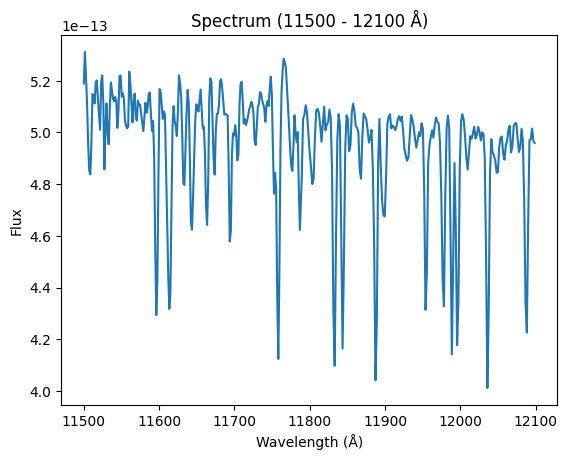

In [3]:
## Reads in data and graphs it so you can vizualize

NAME = 'BMPer.UT240115.csv' # Path to your csv file
RANGE = [11500, 12100] # Range of wavelengths you want to look at in angstroms
GRAPH = True # True for graphing, False for no Graphing

min_wv, max_wv = RANGE
# usecols gives the range of inputs you want, for us we take wavelength and flux
wavelengths, flux = np.loadtxt(NAME, unpack=True, usecols=(0,1), skiprows=1, delimiter=',')
wavelengths *= 10000 # Convert from microns to Angstroms
mask = (wavelengths >= min_wv) & (wavelengths <= max_wv)
wv_trimmed = wavelengths[mask]
flux_trimmed = flux[mask]
    
if GRAPH:
    plt.plot(wv_trimmed, flux_trimmed)
    plt.title(f"Spectrum ({min_wv} - {max_wv} Å)")
    plt.xlabel("Wavelength (Å)")
    plt.ylabel("Flux")
    plt.show()

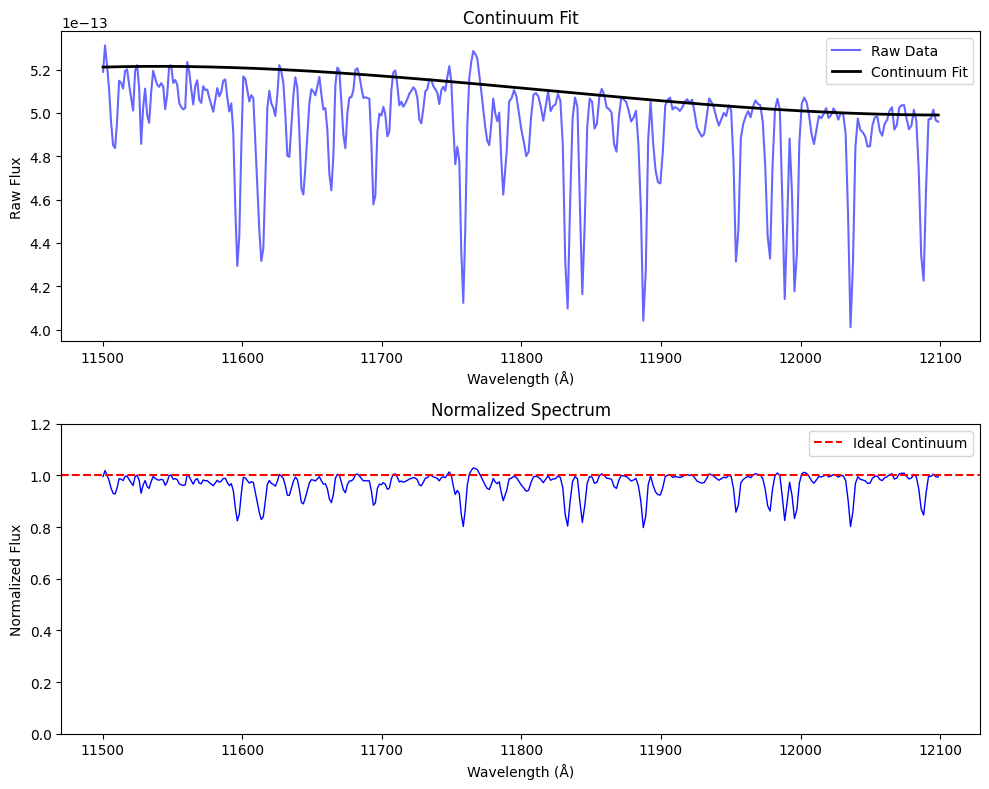

In [4]:
## Normalizes your data using a chebyshev polynomial fit and plots the continuum

DEGREE = 3 # What degree polynomial you want for your fit
SIGMA_LOWER = 1 # How many standard deviations below the fit you want to consider
SIGMA_UPPER = 10 # How many standard deviations above the fit you want to consider
MAXITERS = 20 # Maximum number of iterations for a fit
GRAPH = True # True if you want graph to visualize

model_init = Chebyshev1D(degree=DEGREE)
base_fitter = LinearLSQFitter()
fitter = FittingWithOutlierRemoval(
    base_fitter, 
    SigmaClip(sigma_lower=SIGMA_LOWER, sigma_upper=SIGMA_UPPER, maxiters=MAXITERS) 
)
fitted_model, mask = fitter(model_init, wv_trimmed, flux_trimmed)
continuum_flux = fitted_model(wv_trimmed)
normalized_flux = flux_trimmed / continuum_flux

if GRAPH:
    fig, axs = plt.subplots(2, 1, figsize=(10, 8))

    # Plots fit over the data
    axs[0].plot(wv_trimmed, flux_trimmed, label="Raw Data", color='blue', alpha=0.6)
    axs[0].plot(wv_trimmed, continuum_flux, color='black', linewidth=2, label="Continuum Fit")
    axs[0].set_xlabel("Wavelength (Å)")
    axs[0].set_title("Continuum Fit")
    axs[0].set_ylabel("Raw Flux")
    axs[0].legend()
        
    # Plots normalized spectrum
    axs[1].plot(wv_trimmed, normalized_flux, color='blue', linewidth=1)
    axs[1].axhline(1.0, color='red', linestyle='--', label="Ideal Continuum")
    axs[1].set_title("Normalized Spectrum")
    axs[1].set_xlabel("Wavelength (Å)")
    axs[1].set_ylabel("Normalized Flux")
    axs[1].set_ylim(0, 1.2)
    axs[1].legend()
        
    plt.tight_layout()
    plt.show()

In [5]:
# obs_wl = observed wavelength
# v = velocity in km/s
def redshift(obs_wl, velocity):
    c = 299792 # speed of light
    return obs_wl / (velocity / c + 1) # rest wavelength

In [6]:
## The function we'll use for fitting. KORG has its own fit_spectrum function, and it is packaged in this python function.

def fitting(obs_file):
    ## read in the spectral file which should be in the form of a CSV
    spec = jl.CSV.read(obs_file, jl.DataFrame)
    print(spec)
    ## Convert observed wavelengths (waveobs) using air_to_vacuum. Commented out because it will be accounted for if you shift the spectra.
    #  spec.waveobs = [Korg.air_to_vacuum(w) for w in spec.waveobs]
    
    ## Now provide initial estimates and fixed parameters. It is currently set to have fixed metallicity and free temperature, microturbulence, 
    ## and surface gravity. The metallicity can be standard or by element, e.g. {"C":-0.7, "O":-0.59, "Na":0.4, "Mg":-0.04, "Al":0.110, "Fe":-0.08}
    
    initial_guess = {'Teff': 5300, 'vmic': 4.5, 'logg': 1.3}
    fixed_param = {'M_H': 0.05}
    
    ## Define fitting windows. Set to avoid most of the telluric lines while including many metal lines. Can have multiple windows, for example to 
    ## ignore carbon lines which vary with evolutionary stage: windows = [(11555.9, 11653.8), (11761.8, 11794.0), (11808.0, 11853.5), (11914.8, 12097.0)]

    windows = [(11550, 12100)]
    
    ## Convert the Python list of tuples to a Julia array
    winds = jl.seval(f"{windows}")

    ## Convert from microns to angstroms if necessary
    waveobs = np.asarray(spec.waveobs, dtype=float)
    waveobs = waveobs * 10000
    print(waveobs)
    ## Use KORG's fit_spectrum function
    fit_result = Korg.Fit.fit_spectrum(waveobs, spec.flux, spec.err, linelist, initial_guess, fixed_param, windows=winds, R=3500)
    # note that R is resolving power i.e. wavelength/delta wavelength
    
    ## Extract data within fitting windows
    obs_wl_mask = np.array(fit_result.obs_wl_mask)
    obs_wls = np.array(waveobs)[obs_wl_mask]
    obs_flux = np.array(spec.flux)[obs_wl_mask]
    best_fit_flux = np.array(fit_result.best_fit_flux)

    print(fit_result.best_fit_params)
    return fit_result.best_fit_params, obs_wls, obs_flux, best_fit_flux, waveobs, spec.flux, windows

In [7]:

## This function is for synthesizing the full, best-fit spectrum. KORG currently only provides the best-fit spectrum WITHIN THE FITTING WINDOWS,
## so this will take the best values and return the best-fit spectrum for regions outside the fitting windows.

def synthesize_spectrum(Teff, logg, vmic, linelist, LSF_matrix, synthesis_wls):
    M_H = jl.Korg.format_A_X(0.05)  # Metallicity. Change to reflect what was used in fitting function above.
    atm = jl.Korg.interpolate_marcs(Teff, logg, M_H)
    
    # Synthesize spectrum
    synth_spec = jl.Korg.synthesize(atm, linelist, M_H, synthesis_wls[0], synthesis_wls[-1], 0.1, vmic=vmic)

    synth_wavelengths = np.array(synth_spec.wavelengths)
    synth_flux = np.array(synth_spec.flux)
    synth_cntm = np.array(synth_spec.cntm)
    F = synth_flux/synth_cntm
    
    # Apply the Line-Spread Function (LSF) matrix to the synthesized flux
    synthesized_flux = LSF_matrix @ F

    return synthesized_flux

In [8]:
## In order to generate spectra, the program needs a linelist. These can be generated from 'vald.astro.uu.se/vald.php'.
## Link to the linelist file, in this example it is the 11500 to 13000 Angstrom region. 

linelist = Korg.read_linelist("11500_13000.vald", format="vald")

# Open the file with CSV names. In this example there is only one 'CPCep.UT231015_j.csv'

with open('projecttargets.csv', 'r') as f:
    filelist = [line.strip().split(', ') for line in f]
print(filelist)

[['BMPer.UT240115.csv', '56.8528'], ['RYCas.UT230827.csv', '-26.0522']]


In [10]:
print("obs_wls:", obs_wls) #These are tests to see if the error is in the type, which it might be
print("obs_wls type:", type(obs_wls))

print("velocity_guess:", velocity_guess)
print("velocity_guess type:", type(velocity_guess))

obs_wls: [11550.44794083 11551.88441277 11553.31969261 11554.75616455
 11556.1914444  11557.62791634 11559.06319618 11560.49847603
 11561.93494797 11563.37022781 11564.80550766 11566.2419796
 11567.67725945 11569.11253929 11570.54781914 11571.98309898
 11573.41957092 11574.85485077 11576.29013062 11577.72541046
 11579.16069031 11580.59597015 11582.03125    11583.46652985
 11584.90180969 11586.33708954 11587.77236938 11589.20645714
 11590.64173698 11592.07701683 11593.51229668 11594.94757652
 11596.38166428 11597.81694412 11599.25222397 11600.68631172
 11602.12159157 11603.55567932 11604.99095917 11606.42623901
 11607.86032677 11609.29560661 11610.72969437 11612.16378212
 11613.59906197 11615.03314972 11616.46842957 11617.90251732
 11619.33660507 11620.77069283 11622.20597267 11623.64006042
 11625.07414818 11626.50823593 11627.94232368 11629.37760353
 11630.81169128 11632.24577904 11633.67986679 11635.11395454
 11636.5480423  11637.98213005 11639.4162178  11640.84911346
 11642.28320122 

In [9]:

## Loop through the csv files. Depending on your computer each file will take 5 or more minutes to fit.

# for target in filelist:
target = filelist[0]
print(f"Processing {target[0]}...")

best_fit_params, obs_wls, obs_flux, best_fit_flux, specwls, specflux, windows = fitting(target[0])
Teff = best_fit_params['Teff']
logg = best_fit_params['logg']
vmic0 = best_fit_params['vmic']

print("redshifting...")
velocity_guess = target[1]
obs_wls = redshift(obs_wls, velocity_guess)
print("synthesizing...")
# synthesize full spectrum
synthesis_wls = np.arange(windows[0][0], windows[0][1], 0.1)
LSF_matrix = Korg.compute_LSF_matrix(synthesis_wls, specwls, 3500)

synth_flux = synthesize_spectrum(Teff, logg, vmic0, linelist, LSF_matrix, synthesis_wls)


Processing BMPer.UT240115.csv...
5716×4 DataFrame
  Row │ waveobs   flux           err            question
      │ Float64   Float64        Float64        Float64
──────┼──────────────────────────────────────────────────
    1 │ 0.973324    5.01062e-13    3.81137e-15       0.0
    2 │ 0.973448    4.94282e-13    3.79465e-15       0.0
    3 │ 0.973571    4.99586e-13    3.82592e-15       0.0
    4 │ 0.973695    5.11768e-13    3.87347e-15       0.0
    5 │ 0.973819    5.15267e-13    3.85355e-15       0.0
    6 │ 0.973943    5.15699e-13    3.84738e-15       0.0
    7 │ 0.974066    5.11607e-13    3.97286e-15       0.0
    8 │ 0.97419     4.98344e-13    4.29671e-15       0.0
    9 │ 0.974408    4.80165e-13    3.53648e-15       0.0
   10 │ 0.974554    4.87399e-13    3.38427e-15       0.0
   11 │ 0.974701    5.04867e-13    3.4423e-15        0.0
   12 │ 0.974847    5.03496e-13    3.58981e-15       0.0
   13 │ 0.974994    4.95606e-13    3.8809e-15        0.0
   14 │ 0.97514     4.9839e-13     3.5

┌ Warning: The fit is poorly constrained (condition number of JᵀWJ is 13647.504324762747, above the condition_number_warning_threshold of 1000.0). The best-fit parameters may be unreliable: different parameter combinations likely produce nearly indistinguishable spectra. Consider fitting fewer parameters, or using more/broader wavelength windows to break the degeneracy. (Raise condition_number_warning_threshold to silence this.)
└ @ Korg.Fit C:\Users\ccrun\.julia\packages\Korg\LoLuV\src\Fit\fit_via_synthesis.jl:471


TypeError: unsupported operand type(s) for /: 'str' and 'int'

┌ Warning: These parameters converged to (or very near) their bounds: ["vmic"]. This usually means the fit is under-constrained or the bounds are too tight for this data.
└ @ Korg.Fit C:\Users\ccrun\.julia\packages\Korg\LoLuV\src\Fit\fit_via_synthesis.jl:482


In [ ]:
## Now that it found the best parameters for the observed spectrum, we can compare with the synthetic spectrum having the same parameters.

## find the difference at each wavelength
residuals = specflux - synth_flux

plt.plot(specwls, specflux, label="data")
plt.plot(specwls, synth_flux, label="synth")
plt.plot(obs_wls, best_fit_flux, label="model")
plt.scatter(specwls, residuals, label="residual")
plt.hlines([-0.05,0.05], 11500, 12100, color='r') # a plus/minus of 5% for visual comparison
plt.xlim(11500,12100)
plt.xlabel("Wavelength")
plt.ylabel("Flux")
plt.legend()
plt.title("Observed Spectrum vs. Model Fit")
#plt.savefig('fit_results_data/' f"{os.path.splitext(os.path.basename(target))[0]}_plot.png")  ## if you want to save the figure
plt.show()

In [ ]:
## look closer at the residuals. If you have large spikes above and below, it is likely to be because your spectrum wasn't shifted properly.

plt.scatter(specwls, residuals, label="residual")
plt.xlabel("Wavelength")
plt.ylabel("Residual")
plt.ylim(-0.1,0.1)
plt.legend()
plt.show()

The KORG guide for fitting  (https://ajwheeler.github.io/Korg.jl/stable/generated/tutorials/Direct%20Fitting/) has other diagnostics for looking at the fitting routine. You'll need to translate to python since these guides are mostly in julia.